   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Shape: (1338, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
X shape: (1338, 8)
y shape: (1338,)
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0     False        True             False   
1   18  33.770         1      True       False             False   
2   28  33.000         3      True       False             False   
3   33  22.705         0      True       False              True   
4   32  28.880         0      True       False              True   

   region_southeast  region_southwest  
0             False              True  


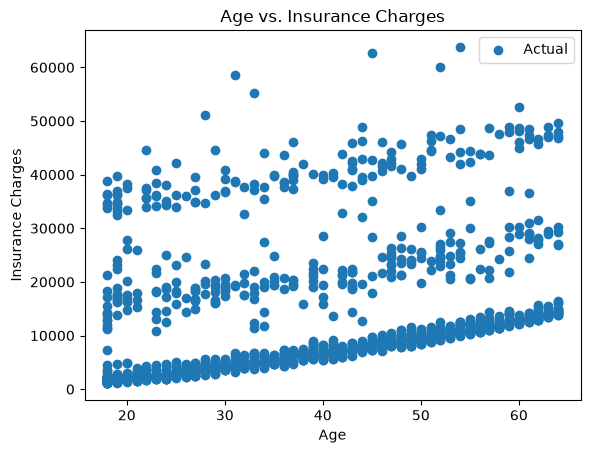

X_train shape: (1070, 8)
X_test shape: (268, 8)
Coefficients: [ 2.56975706e+02  3.37092552e+02  4.25278784e+02 -1.85916916e+01
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]
Intercept: -11931.219050326681
   Actual Charges  Predicted Charges
0      9095.06825        8969.550274
1      5272.17580        7068.747443
2     29330.98315       36858.410912
3      9301.89355        9454.678501
4     33750.29180       26973.173457
5      4536.25900       10864.113164
6      2117.33885         170.280841
7     14210.53595       16903.450287
8      3732.62510        1092.430936
9     10264.44210       11218.343184
MAE: 4181.1944737536505
R2: 0.7835929767120724


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("insurance.csv")

print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

X = df.drop(columns=["charges"])
y = df["charges"]

X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

plt.scatter(df["age"], df["charges"], label="Actual")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Age vs. Insurance Charges")
plt.legend()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

pred = model.predict(X_test)
comparison = pd.DataFrame({
    "Actual Charges": y_test.values,
    "Predicted Charges": pred
})
print(comparison.head(10))

mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print("MAE:", mae)
print("R2:", r2)

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(

n_estimators=100, random_state=42

)

cv = StratifiedKFold(

n_splits=5, shuffle=True, random_state=42

)

scores = cross_val_score(

model, X_train, y_train, cv=cv, scoring="accuracy"

)

print("Fold scores:", scores.round(3))

print("Mean accuracy:", round(scores.mean(), 3))

NameError: name 'X_train' is not defined

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Shape: (1338, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

X shape: (1338, 8)
y shape: (1338,)
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0     False        True             False   
1   18  33.770         1      True       False             False   
2   28  33.000         3      True       False             False   
3   33  22.705         0      True       False              True   
4   32  28.880         0      True       False              True   

   region_southeast  region_southwest  
0             False              True 

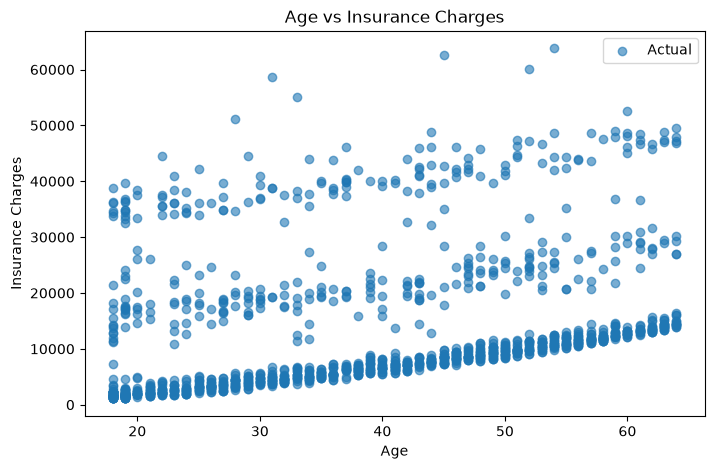


X_train shape: (1070, 8)
X_test shape: (268, 8)
y_train shape: (1070,)
y_test shape: (268,)

Cross Validation Results
Fold R² Scores: [0.805 0.819 0.873 0.809 0.841]
Mean R² Score: 0.83

Model trained successfully!

Actual vs Predicted Charges
   Actual Charges  Predicted Charges
0      9095.06825        9632.922503
1      5272.17580        5581.934399
2     29330.98315       28192.543908
3      9301.89355       12642.494730
4     33750.29180       34640.363728
5      4536.25900        8159.653025
6      2117.33885        2099.045651
7     14210.53595       14571.044028
8      3732.62510        5617.644674
9     10264.44210       10797.874756

Model Evaluation
MAE : 2546.26
RMSE: 4574.14
R²  : 0.865

Top Feature Importances
            Feature  Importance
4        smoker_yes    0.608618
1               bmi    0.216634
0               age    0.134363
2          children    0.019317
3          sex_male    0.006259
5  region_northwest    0.005531
6  region_southeast    0.005312
7  region

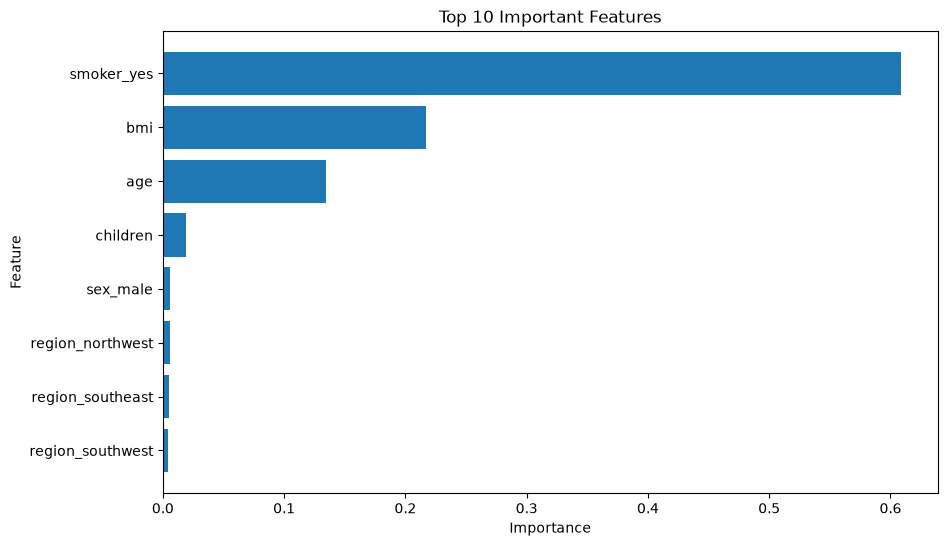

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
df = pd.read_csv("insurance.csv")

# Display dataset information
print(df.head())
print("\nShape:", df.shape)
print("Columns:", df.columns.tolist())

# Features and target
X = df.drop(columns=["charges"])
y = df["charges"]

# Convert categorical variables to numeric
X = pd.get_dummies(X, drop_first=True)

print("\nX shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

# Visualization
plt.figure(figsize=(8, 5))
plt.scatter(df["age"], df["charges"], alpha=0.6, label="Actual")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Age vs Insurance Charges")
plt.legend()
plt.show()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Random Forest Regressor Model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# 5-Fold Cross Validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("\nCross Validation Results")
print("Fold R² Scores:", np.round(cv_scores, 3))
print("Mean R² Score:", round(cv_scores.mean(), 3))

# Train the model
model.fit(X_train, y_train)

# Model parameters
print("\nModel trained successfully!")

# Predictions
pred = model.predict(X_test)

# Compare actual vs predicted values
comparison = pd.DataFrame({
    "Actual Charges": y_test.values,
    "Predicted Charges": pred
})

print("\nActual vs Predicted Charges")
print(comparison.head(10))

# Evaluation metrics
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("\nModel Evaluation")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 3))

# Feature Importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nTop Feature Importances")
print(feature_importance.head(10))

# Plot Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"][:10],
    feature_importance["Importance"][:10]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")
plt.gca().invert_yaxis()
plt.show()

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)


pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])


cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
print(f"5-Fold CV Scores: {cv_scores}")
print(f"Baseline Mean CV Accuracy: {cv_scores.mean():.4f}")


param_grid = {
    'clf__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print(f"\nBest Parameters: {grid.best_params_}")
print(f"Tuned Mean CV Accuracy: {grid.best_score_:.4f}")


pipe.fit(X_train, y_train)
print(f"\nBaseline Validation Accuracy: {pipe.score(X_valid, y_valid):.4f}")
print(f"Tuned Validation Accuracy: {grid.best_estimator_.score(X_valid, y_valid):.4f}")

print(f"\nBaseline Test Accuracy: {pipe.score(X_test, y_test):.4f}")
print(f"Tuned Test Accuracy: {grid.best_estimator_.score(X_test, y_test):.4f}")

5-Fold CV Scores: [0.9875     0.95       0.9875     0.98734177 0.98734177]
Baseline Mean CV Accuracy: 0.9799

Best Parameters: {'clf__C': 1}
Tuned Mean CV Accuracy: 0.9799

Baseline Validation Accuracy: 0.9882
Tuned Validation Accuracy: 0.9882

Baseline Test Accuracy: 0.9884
Tuned Test Accuracy: 0.9884
